In [1]:
pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
# fetch dataset
real_estate_valuation=fetch_ucirepo(id=477)
#data (as pandas dataframes)
X=real_estate_valuation.data.features
Y=real_estate_valuation.data.targets
# metadata
print(real_estate_valuation.metadata)
# variable information
print(real_estate_valuation.variables)
#δημιουργια ενιαιου data frame
df= pd.concat([X,Y], axis=1)
print (df.head())

{'uci_id': 477, 'name': 'Real Estate Valuation', 'repository_url': 'https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set', 'data_url': 'https://archive.ics.uci.edu/static/public/477/data.csv', 'abstract': 'The real estate valuation is a regression problem. The market historical data set of real estate valuation are collected from Sindian Dist., New Taipei City, Taiwan. ', 'area': 'Business', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 414, 'num_features': 6, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Y house price of unit area'], 'index_col': ['No'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2018, 'last_updated': 'Mon Feb 26 2024', 'dataset_doi': '10.24432/C5J30W', 'creators': ['I-Cheng Yeh'], 'intro_paper': {'ID': 373, 'type': 'NATIVE', 'title': 'Building real estate valuation models with comparative approach through case-based reasoning', 'authors': 'I. Yeh

In [3]:
#ελεγχος για υπαρξη ελλιπων τιμων (1.3)
print(df.isnull().values.any())

False


In [4]:
rows,columns =df.shape
print(f"το πληθος των γραμμων ειναι:{rows}")
print(f"το πληθος των στηλων ειναι:{columns}")


το πληθος των γραμμων ειναι:414
το πληθος των στηλων ειναι:7


Υπάρχουν 0 διπλοτυπες εγγραφές.


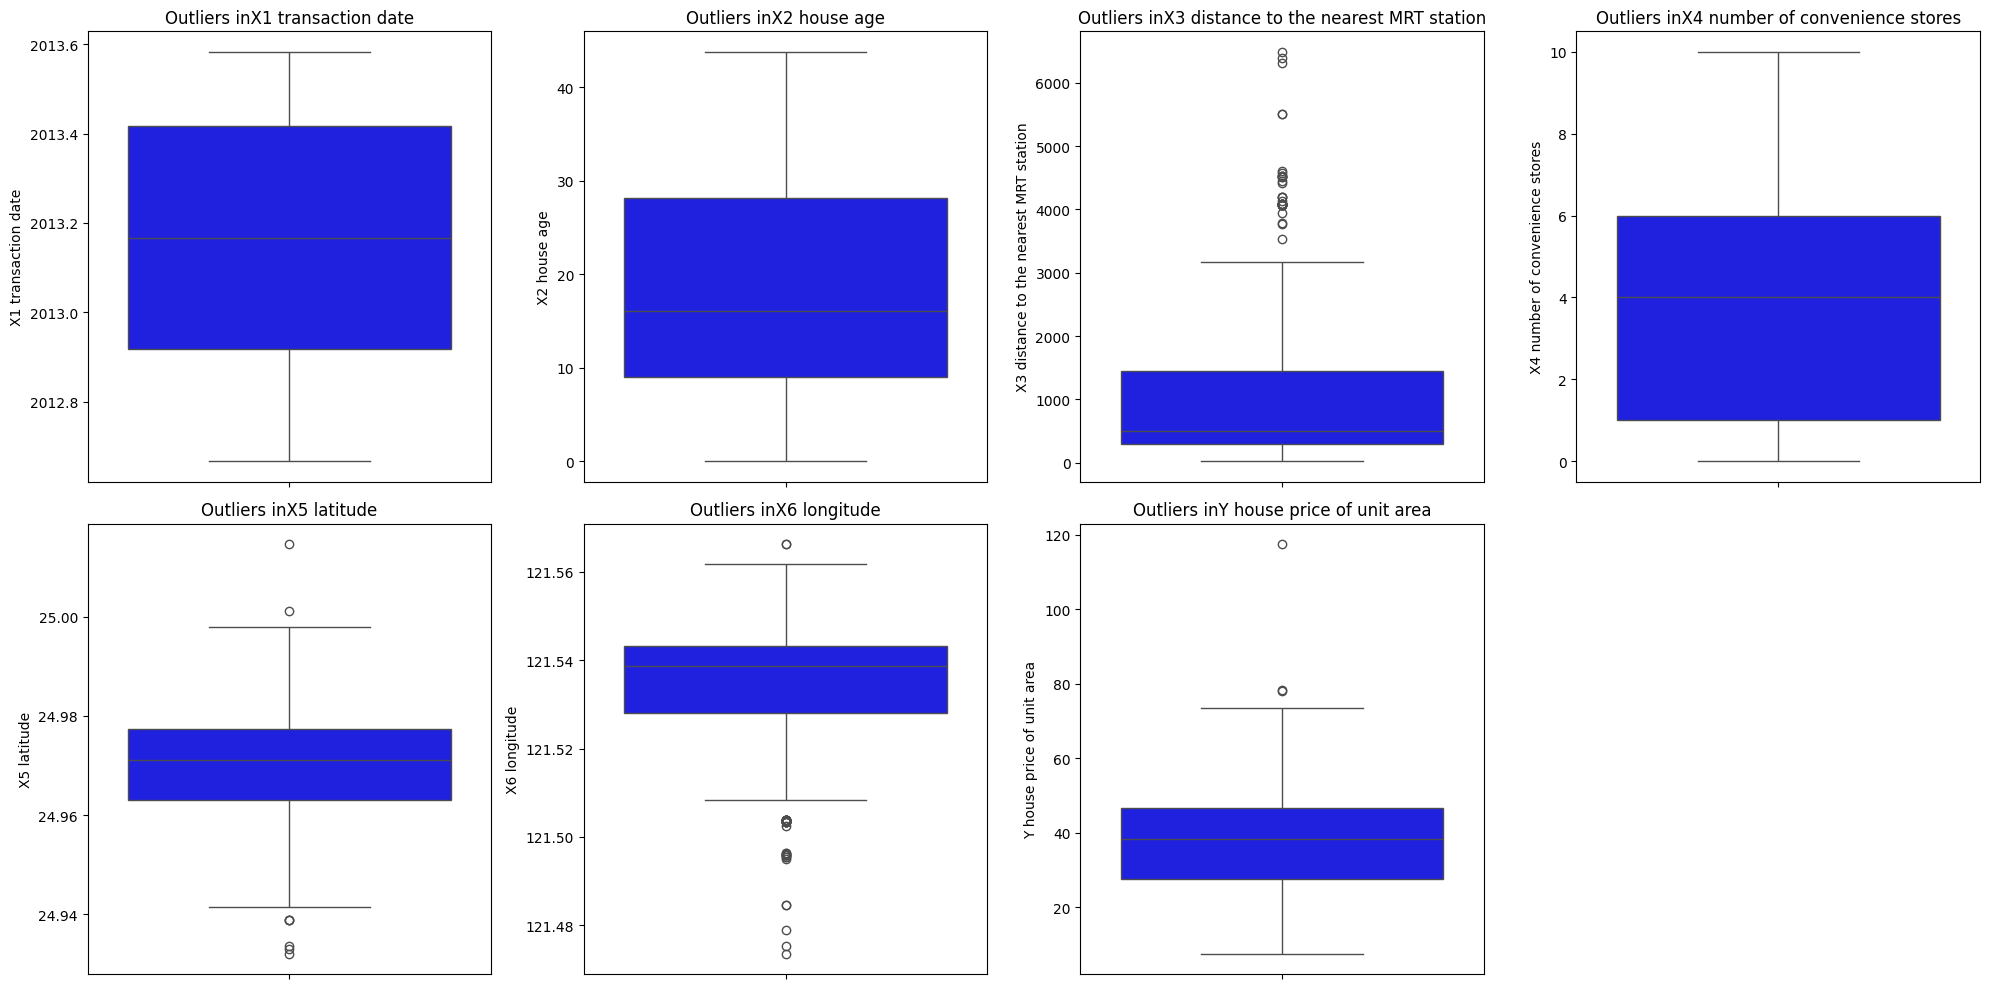

In [5]:
#ελεγχος για διπλότυπες εγγραφες και boxplot για ελεγχο ακραίων τιμών (1.4)
duplicates = df.duplicated().sum()
print(f"Υπάρχουν {duplicates} διπλοτυπες εγγραφές.")
columnstocheck= df.columns
plt.figure(figsize=(20,10))
for i, col in enumerate(columnstocheck):
  plt.subplot(2,4,i+1)
  sns.boxplot(data=df, y=col, color='blue')
  plt.title(f"Outliers in{col}")
plt.tight_layout()
plt.show()


In [6]:
#ελεγχος για ακραιες τιμες (1.4)
def count_outliers_summary(dataframe):
    outlier_counts = {}

    for col in dataframe.select_dtypes(include=['number']).columns:
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Καταμέτρηση τιμών εκτός ορίων
        count = ((dataframe[col] < lower_bound) | (dataframe[col] > upper_bound)).sum()
        outlier_counts[col] = count

    return pd.DataFrame.from_dict(outlier_counts, orient='index', columns=['Outlier Count'])

# Εμφάνιση αποτελεσμάτων
print("Συγκεντρωτικός αριθμός ακραίων τιμών ανά μεταβλητή:")
print(count_outliers_summary(df))

Συγκεντρωτικός αριθμός ακραίων τιμών ανά μεταβλητή:
                                        Outlier Count
X1 transaction date                                 0
X2 house age                                        0
X3 distance to the nearest MRT station             37
X4 number of convenience stores                     0
X5 latitude                                         8
X6 longitude                                       35
Y house price of unit area                          3


In [7]:
#Παρουσιαση βασικων περιγραφικων χαρακτηριστικων για ολες τις μεταβλητες (1.5)
pd.set_option("display.float_format", lambda x:"%.3f"% x)
d_stats=df.describe()
print("Βασικα Περιγραφικα Χαρακτηριστικα:")
print(d_stats)


Βασικα Περιγραφικα Χαρακτηριστικα:
       X1 transaction date  X2 house age  \
count              414.000       414.000   
mean              2013.149        17.713   
std                  0.282        11.392   
min               2012.667         0.000   
25%               2012.917         9.025   
50%               2013.167        16.100   
75%               2013.417        28.150   
max               2013.583        43.800   

       X3 distance to the nearest MRT station  \
count                                 414.000   
mean                                 1083.886   
std                                  1262.110   
min                                    23.383   
25%                                   289.325   
50%                                   492.231   
75%                                  1454.279   
max                                  6488.021   

       X4 number of convenience stores  X5 latitude  X6 longitude  \
count                          414.000      414.000      

In [8]:
#Υπολογισμός των στατιστικών (1.5)
descriptive_stats = df.describe().T

descriptive_stats = descriptive_stats.round(2)
print("Πίνακας Περιγραφικών Στατιστικών για την Αναφορά:")
display(descriptive_stats)
descriptive_stats.to_excel("ds.xlsx")

Πίνακας Περιγραφικών Στατιστικών για την Αναφορά:


,count,mean,std,min,25%,50%,75%,max
X1 transaction date,414.000,2013.150,0.280,2012.670,2012.920,2013.170,2013.420,2013.580
X2 house age,414.000,17.710,11.390,0.000,9.020,16.100,28.150,43.800
X3 distance to the nearest MRT station,414.000,1083.890,1262.110,23.380,289.320,492.230,1454.280,6488.020
X4 number of convenience stores,414.000,4.090,2.950,0.000,1.000,4.000,6.000,10.000
X5 latitude,414.000,24.970,0.010,24.930,24.960,24.970,24.980,25.010
X6 longitude,414.000,121.530,0.020,121.470,121.530,121.540,121.540,121.570
Y house price of unit area,414.000,37.980,13.610,7.600,27.700,38.450,46.600,117.500


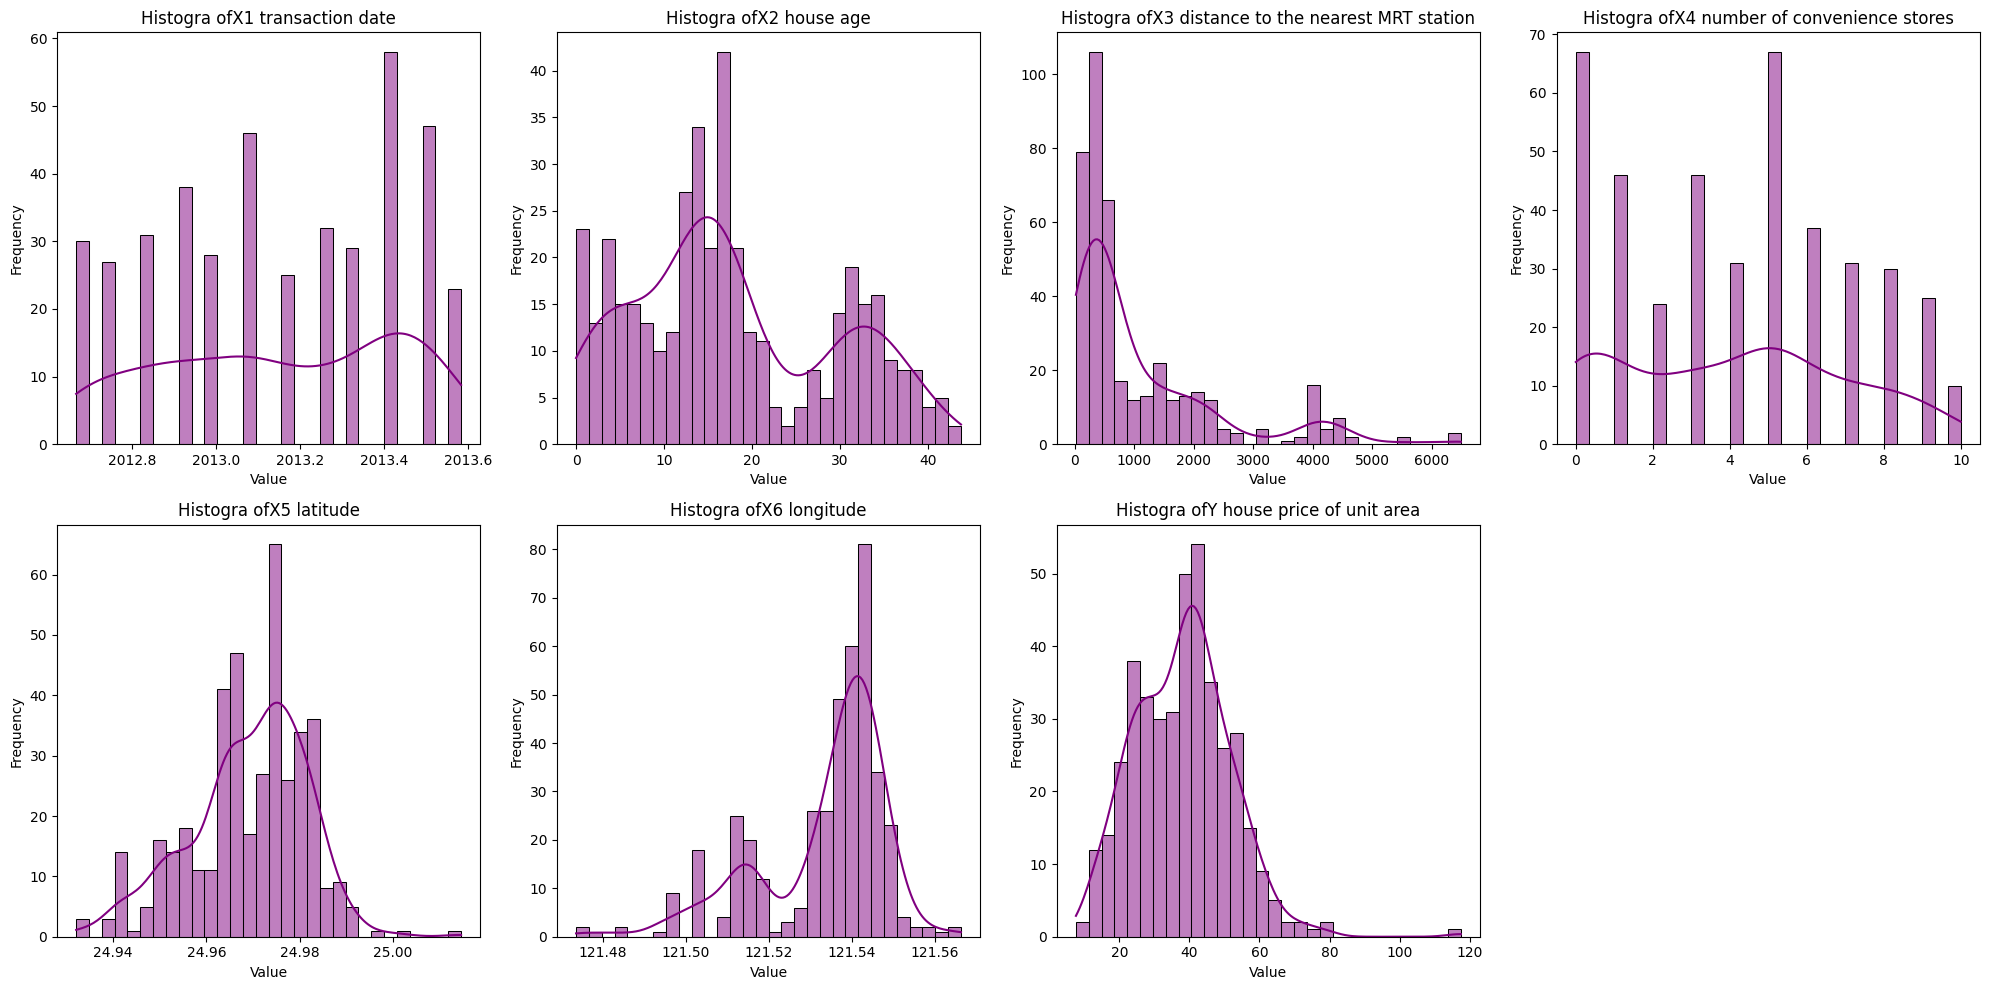

In [9]:
# ιστογραμματα(1.6)
columnstoplot=df.columns
plt.figure(figsize=(20,10))
for i, col in enumerate(columnstoplot):
  plt.subplot(2,4,i+1)
  sns.histplot(df[col], kde=True, color="purple", bins=30)
  plt.title(f"Histogra of{col}")
  plt.xlabel('Value')
  plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

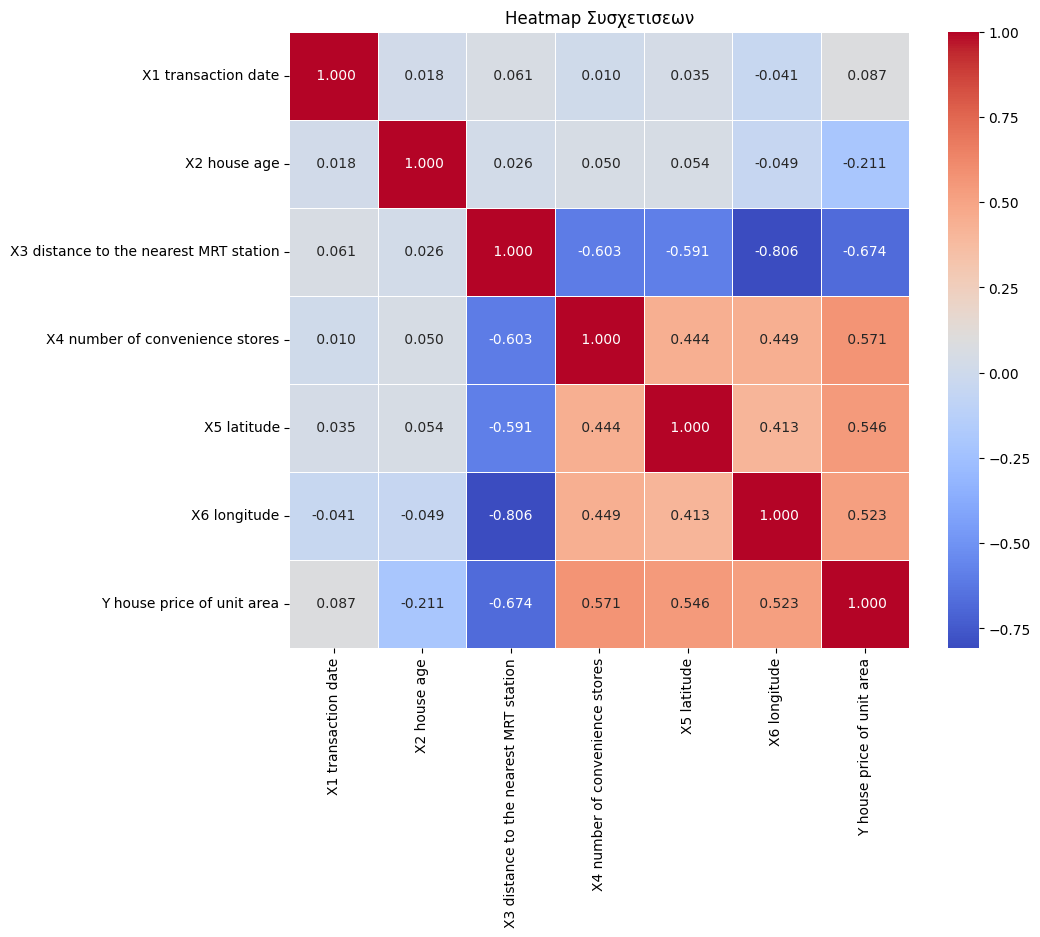

In [10]:
#Heatmap Συσχετίσεων(1.6)
corr_matrix=df.corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm', fmt=" .3f", linewidths=0.5)
plt.title("Heatmap Συσχετισεων")
plt.show()

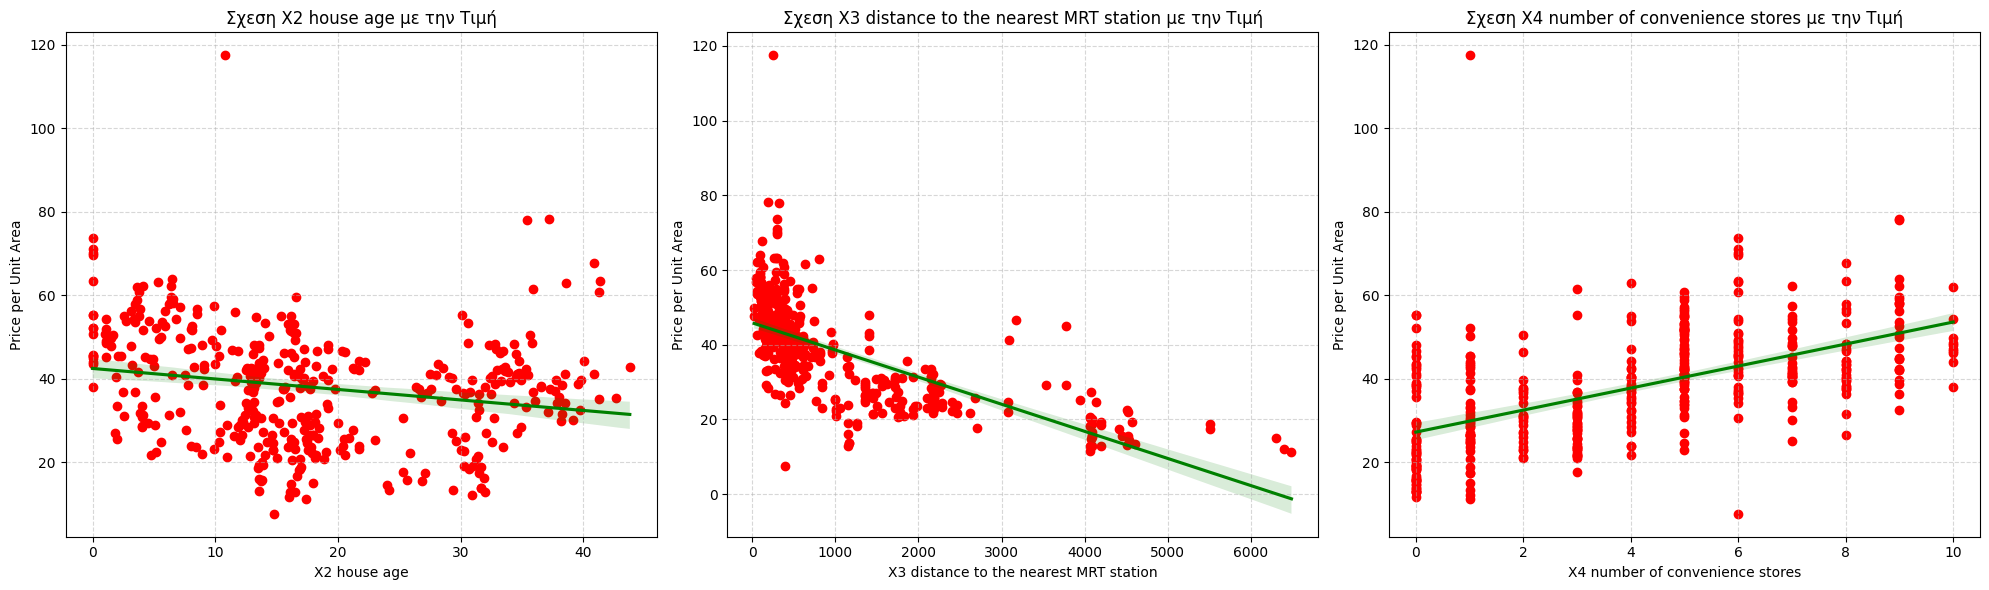

In [11]:
#διαγραμματα διασπορας (Scatter Plots) (1.6)
important_feat=[
    'X2 house age',
    'X3 distance to the nearest MRT station',
    'X4 number of convenience stores'
  ]
plt.figure(figsize=(20,6))
for i, col in enumerate(important_feat):
  plt.subplot(1,3,i+1)
  sns.regplot(data=df, x=col, y='Y house price of unit area',
              scatter_kws={'alpha':1, 'color':'red'},
              line_kws={'color':'green'})

  plt.title(f'Σχεση {col} με την Τιμή')
  plt.xlabel(col)
  plt.ylabel('Price per Unit Area')
  plt.grid(True, linestyle='--',alpha=0.5)
plt.tight_layout()
plt.show()


In [12]:
#διαχωρισμός δεδομένων σε σύνολο εκπαιδευσης και σύνολο ελέγχου (2.1)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test= train_test_split(X,Y, test_size=0.2, random_state=42)
print(f"Το δείγμα εκπαιδευσης (X_train): {X_train.shape[0]}")
print(f"Το δειγμα ελέγχου (Y_test):{X_test.shape[0]} ")


Το δείγμα εκπαιδευσης (X_train): 331
Το δειγμα ελέγχου (Y_test):83 


In [13]:
#τυποποιηση (2.2)
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
print("Μετα την τυποποιηση:")
print(f"Μεση τιμη του X_train scaled:{X_train_scaled.mean():.2f}")
print(f"Τυπικη Απόκλιση του X_train_scaled:{X_train_scaled.std():.2f}")


Μετα την τυποποιηση:
Μεση τιμη του X_train scaled:-0.00
Τυπικη Απόκλιση του X_train_scaled:1.00


In [14]:
#Δημιουργια baseline μοντελων (3.2,3.3)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
models={
    "Linear Regression":LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
    }
results_list=[]
for name,model in models.items():
  model.fit(X_train_scaled, y_train.values.ravel())
  predictions=model.predict(X_test_scaled)
  #υπολογισμος των μετρικων
  mae=mean_absolute_error(y_test, predictions)
  mse=mean_squared_error(y_test, predictions)
  rmse=np.sqrt(mse)
  r2=r2_score(y_test, predictions)
  results_list.append({
      "Model":name,
      "MAE":mae,
      "MSE":mse,
      "RMSE":rmse,
      "R2 score":r2
  })
results_df=pd.DataFrame(results_list)
print(results_df.to_string(index=False))


            Model   MAE    MSE  RMSE  R2 score
Linear Regression 5.305 53.506 7.315     0.681
    Decision Tree 5.931 66.471 8.153     0.604
    Random Forest 3.964 32.557 5.706     0.806
Gradient Boosting 3.904 34.156 5.844     0.796


In [15]:
#Διασταυρούμενη Επικύρωση (4.1,4.2)

from sklearn.model_selection import cross_validate
import numpy as np
import pandas as pd

cv_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

scoring = {
    'mae': 'neg_mean_absolute_error',
    'mse': 'neg_mean_squared_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

full_cv_results_list = []

for name, model in cv_models.items():
    # Εκτέλεση cross-validation
    cv_results = cross_validate(model, X_train_scaled, y_train.values.ravel(), cv=5, scoring=scoring)

    # Υπολογισμός Mean και Std για κάθε μετρική
    full_cv_results_list.append({
        "Model": name,
        "R2 (Mean)": cv_results['test_r2'].mean(),
        "R2 (Std)":  cv_results['test_r2'].std(),
        "MAE (Mean)": (-cv_results['test_mae']).mean(),
        "MAE (Std)":  cv_results['test_mae'].std(), # Η απόκλιση παραμένει ίδια είτε θετική είτε αρνητική
        "RMSE (Mean)": (-cv_results['test_rmse']).mean(),
        "RMSE (Std)":  cv_results['test_rmse'].std(),
        "MSE (Mean)": (-cv_results['test_mse']).mean(),
        "MSE (Std)":  cv_results['test_mse'].std()
    })

full_cv_df = pd.DataFrame(full_cv_results_list)
print(full_cv_df.to_string(index=False))
full_cv_df.to_excel("cross_validation.xlsx", index=False)


            Model  R2 (Mean)  R2 (Std)  MAE (Mean)  MAE (Std)  RMSE (Mean)  RMSE (Std)  MSE (Mean)  MSE (Std)
Linear Regression      0.540     0.087       6.445      0.432        9.179       1.419      86.271     28.308
    Decision Tree      0.301     0.450       6.600      1.565       10.759       3.194     125.952     76.886
    Random Forest      0.631     0.124       5.171      0.728        8.138       1.738      69.254     29.176
Gradient Boosting      0.635     0.101       5.242      0.517        8.129       1.651      68.811     28.487


In [16]:
# επιλογή μεταβλητών(5.1,5.2)
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestRegressor

correlations = df.corr()['Y house price of unit area'].drop('Y house price of unit area')
filter_selected_features = correlations[abs(correlations) > 0.4].index.tolist()

print(f"Filter Method - Επιλεγμένες μεταβλητές: {filter_selected_features}")

selector = SelectFromModel(RandomForestRegressor(random_state=42), threshold="median")
selector.fit(X_train_scaled, y_train.values.ravel())

embedded_selected_features = X.columns[selector.get_support()].tolist()

print(f"Embedded Method - Επιλεγμένες μεταβλητές: {embedded_selected_features}")


model_all = RandomForestRegressor(random_state=42)
model_all.fit(X_train_scaled, y_train.values.ravel())
score_all = model_all.score(X_test_scaled, y_test)

X_train_selected = selector.transform(X_train_scaled)
X_test_selected = selector.transform(X_test_scaled)

model_selected = RandomForestRegressor(random_state=42)
model_selected.fit(X_train_selected, y_train.values.ravel())
score_selected = model_selected.score(X_test_selected, y_test)

print("Σύγκριση Απόδοσης (R2 Score)")
print(f"Με όλα τα χαρακτηριστικά: {score_all:.4f}")
print(f"Με επιλεγμένα χαρακτηριστικά: {score_selected:.4f}")

Filter Method - Επιλεγμένες μεταβλητές: ['X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude']
Embedded Method - Επιλεγμένες μεταβλητές: ['X2 house age', 'X3 distance to the nearest MRT station', 'X5 latitude']
Σύγκριση Απόδοσης (R2 Score)
Με όλα τα χαρακτηριστικά: 0.8059
Με επιλεγμένα χαρακτηριστικά: 0.7879


In [19]:
#ερωτημα 6
from sklearn.model_selection import GridSearchCV
# Παράμετροι για το Random Forest
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

# Παράμετροι για το Gradient Boosting
gb_param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1],
    'max_depth': [3, 5]
}

# Αναζήτηση για Random Forest
grid_rf = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=5, scoring='r2')
grid_rf.fit(X_train_scaled, y_train.values.ravel())

# Αναζήτηση για Gradient Boosting
grid_gb = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_param_grid, cv=5, scoring='r2')
grid_gb.fit(X_train_scaled, y_train.values.ravel())

# 6.4 Παρουσίαση αποτελεσμάτων
print("Βέλτιστες Υπερπαράμετροι ")
print(f"Random Forest: {grid_rf.best_params_}")
print(f"Gradient Boosting: {grid_gb.best_params_}")



Βέλτιστες Υπερπαράμετροι 
Random Forest: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Συνάρτηση για τον υπολογισμό όλων των μετρικών στο test set
def get_all_metrics(model, X, y):
    predictions = model.predict(X)
    mae = mean_absolute_error(y, predictions)
    mse = mean_squared_error(y, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y, predictions)
    return {"R2": r2, "MAE": mae, "MSE": mse, "RMSE": rmse}

metrics_before = {
    "Random Forest (Πριν)": {"R2": 0.8060, "MAE": 3.964, "MSE": 32.557, "RMSE": 5.706},
    "Gradient Boosting (Πριν)": {"R2": 0.7960, "MAE": 3.904, "MSE": 34.156, "RMSE": 5.844}
}

best_rf_model = grid_rf.best_estimator_
best_gb_model = grid_gb.best_estimator_

rf_after = get_all_metrics(best_rf_model, X_test_scaled, y_test)
gb_after = get_all_metrics(best_gb_model, X_test_scaled, y_test)

# 4. Πίνακας σύγκρισης
final_comparison = [
    {"Μοντέλο": "Random Forest (Πριν)", **metrics_before["Random Forest (Πριν)"]},
    {"Μοντέλο": "Random Forest (Μετά)", **rf_after},
    {"Μοντέλο": "Gradient Boosting (Πριν)", **metrics_before["Gradient Boosting (Πριν)"]},
    {"Μοντέλο": "Gradient Boosting (Μετά)", **gb_after}
]

results_df = pd.DataFrame(final_comparison)
print("--- Πλήρης Σύγκριση Μετρικών (Πριν vs Μετά το Tuning) στο Test Set ---")
print(results_df.to_string(index=False))

# Εξαγωγή σε Excel
results_df.to_excel("hyperparameter_tuning_results.xlsx", index=False)

--- Πλήρης Σύγκριση Μετρικών (Πριν vs Μετά το Tuning) στο Test Set ---
                 Μοντέλο    R2   MAE    MSE  RMSE
    Random Forest (Πριν) 0.806 3.964 32.557 5.706
    Random Forest (Μετά) 0.813 3.859 31.302 5.595
Gradient Boosting (Πριν) 0.796 3.904 34.156 5.844
Gradient Boosting (Μετά) 0.796 3.904 34.156 5.844


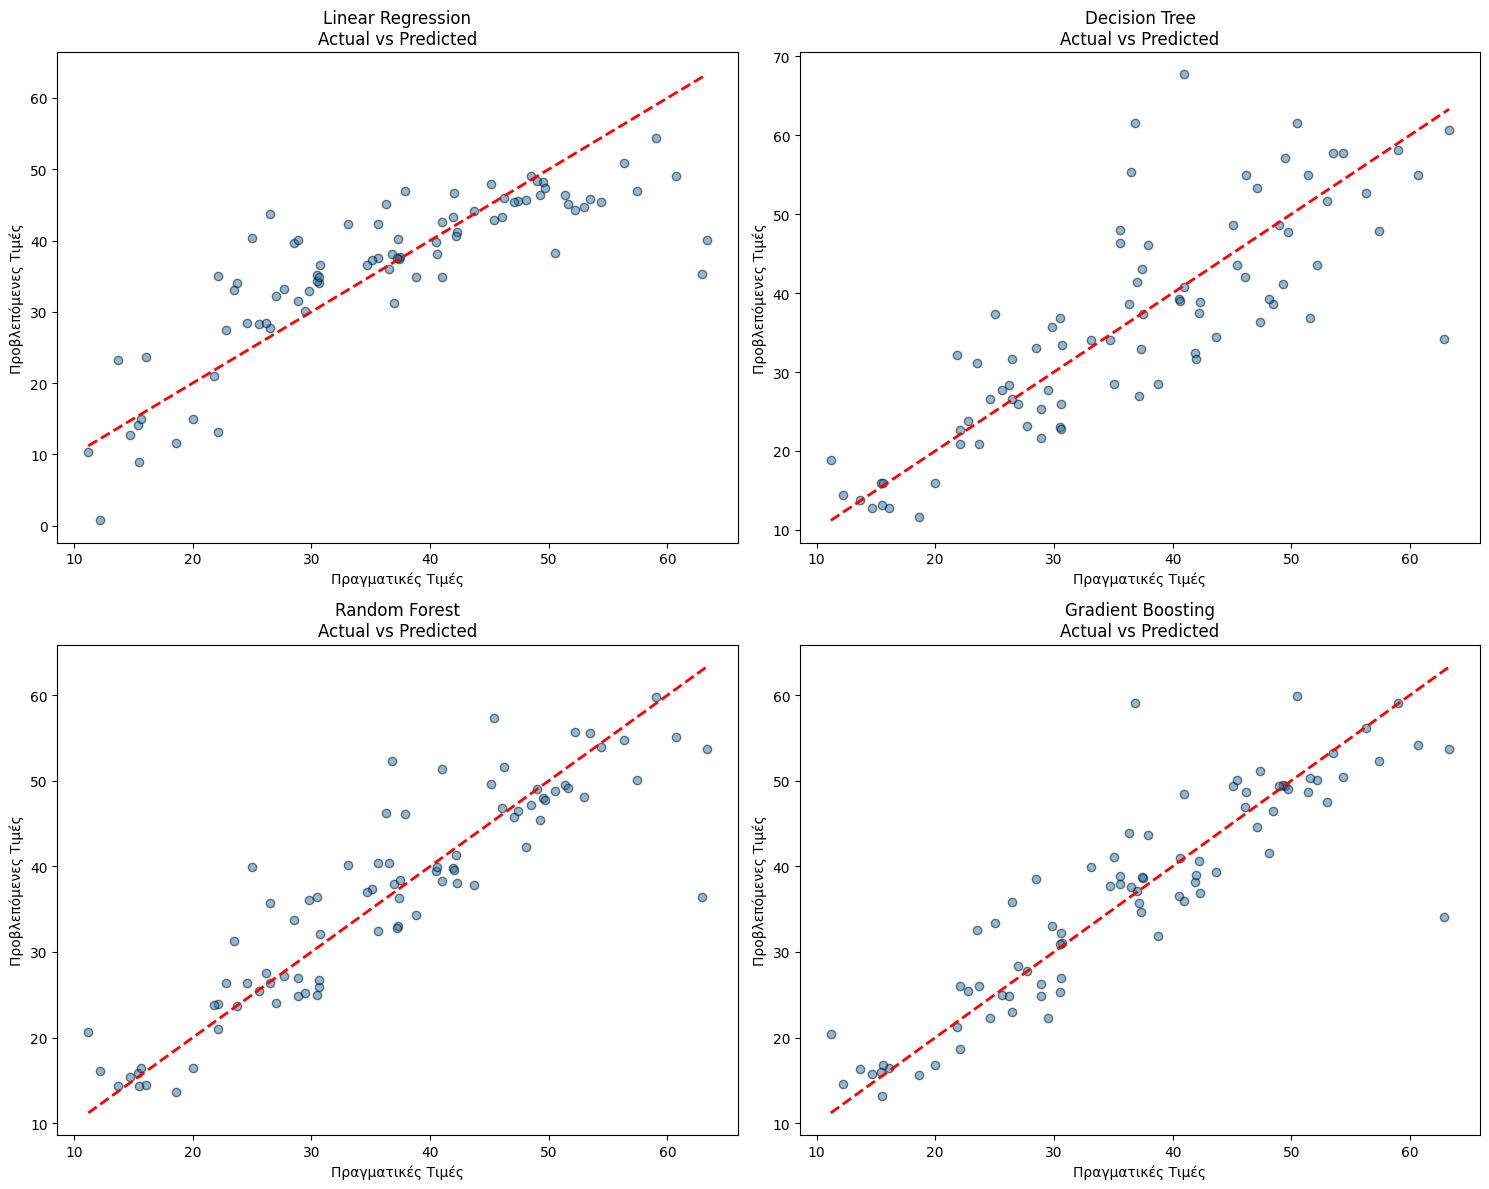

In [ ]:
#ερωτημα 7 (διαγραμμα πραγματικων εναντι προβλεπομενων τιμων)
import matplotlib.pyplot as plt

# 1. Λίστα με τα ονόματα των μοντέλων που εκπαιδεύσαμε στο Ζητούμενο 3
models_to_plot = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()
for i, (name, model) in enumerate(models_to_plot.items()):
    # Εκπαίδευση και Πρόβλεψη
    model.fit(X_train_scaled, y_train.values.ravel())
    y_pred = model.predict(X_test_scaled)

    # Σχεδίαση Scatter Plot
    axes[i].scatter(y_test, y_pred, alpha=0.5, edgecolors='k')

    # Σχεδίαση της διαγωνίου (Ιδανική πρόβλεψη: y_test == y_pred)
    axes[i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

    axes[i].set_title(f'{name}\nActual vs Predicted')
    axes[i].set_xlabel('Πραγματικές Τιμές')
    axes[i].set_ylabel('Προβλεπόμενες Τιμές')

plt.tight_layout()
plt.show()

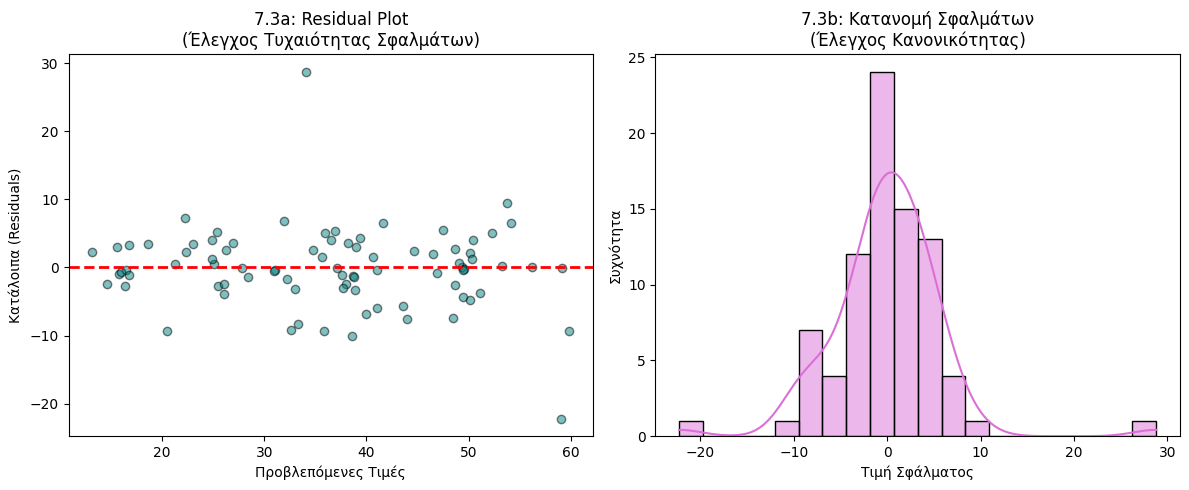

7.5: Οι 3 παρατηρήσεις με το μεγαλύτερο σφάλμα
    Πραγματική_Τιμή  Πρόβλεψη  Απόλυτο_Σφάλμα
14           62.900    34.105          28.795
71           36.800    59.053          22.253
25           28.500    38.567          10.067


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ορισμός του καλύτερου μοντέλου
best_model = grid_gb.best_estimator_
y_pred = best_model.predict(X_test_scaled)

# 7.2 Υπολογισμός των καταλοίπων (residuals)
residuals = y_test.values.flatten() - y_pred

# Δημιουργία γραφημάτων
plt.figure(figsize=(12, 5))

# 7.3 Residual Plot
plt.subplot(1, 2, 1)
plt.scatter(y_pred, residuals, alpha=0.5, color='teal', edgecolors='k')
plt.axhline(y=0, color='red', linestyle='--', lw=2)
plt.xlabel('Προβλεπόμενες Τιμές')
plt.ylabel('Κατάλοιπα (Residuals)')
plt.title('7.3a: Residual Plot\n(Έλεγχος Τυχαιότητας Σφαλμάτων)')

# 7.3 Histogram
plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True, color='orchid')
plt.xlabel('Τιμή Σφάλματος')
plt.ylabel('Συχνότητα')
plt.title('7.3b: Κατανομή Σφαλμάτων\n(Έλεγχος Κανονικότητας)')

plt.tight_layout()
plt.show()

# 7.5 Εντοπισμός 3 παρατηρήσεων με το μεγαλύτερο σφάλμα=
error_analysis = pd.DataFrame({
    'Πραγματική_Τιμή': y_test.values.flatten(),
    'Πρόβλεψη': y_pred.flatten(),
    'Απόλυτο_Σφάλμα': np.abs(residuals)
})

top_3_outliers = error_analysis.sort_values(by='Απόλυτο_Σφάλμα', ascending=False).head(3)

print("7.5: Οι 3 παρατηρήσεις με το μεγαλύτερο σφάλμα")
print(top_3_outliers)


8.1 Συντελεστές Γραμμικού Μοντέλου ---
                                  Feature  Coefficient
3         X4 number of convenience stores        3.219
4                             X5 latitude        2.855
0                     X1 transaction date        1.530
5                            X6 longitude       -0.441
1                            X2 house age       -3.063
2  X3 distance to the nearest MRT station       -5.787


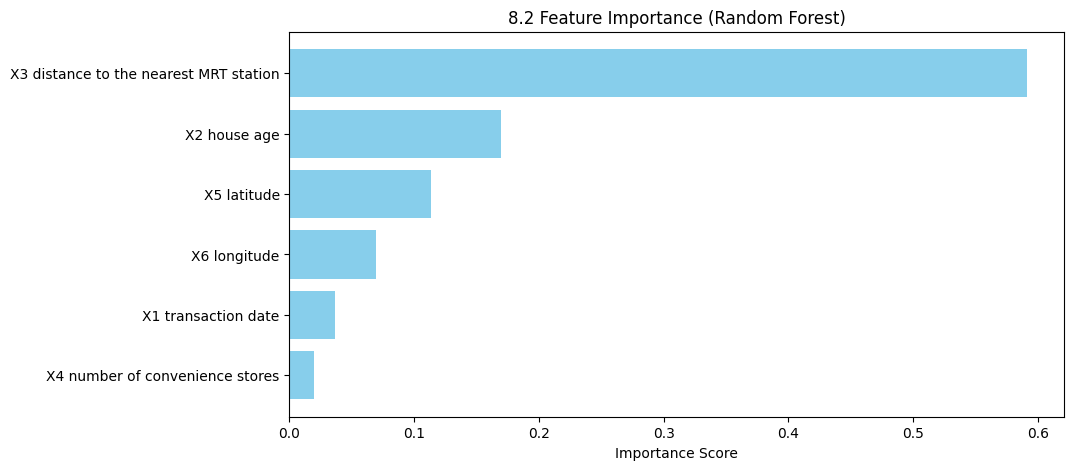


--- 8.4 SHAP Summary Plot ---


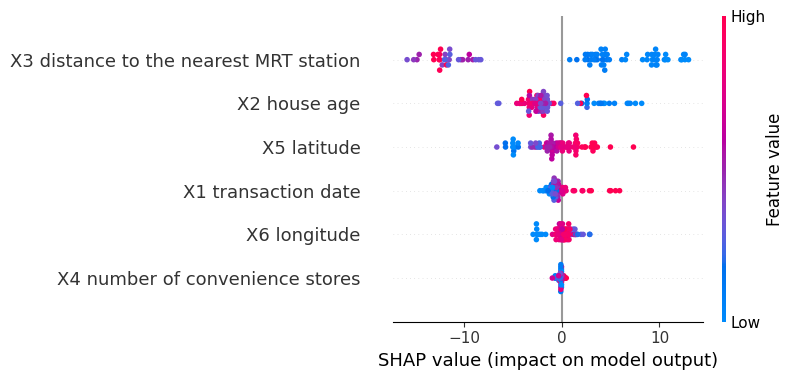


--- 8.4 SHAP Bar Plot ---


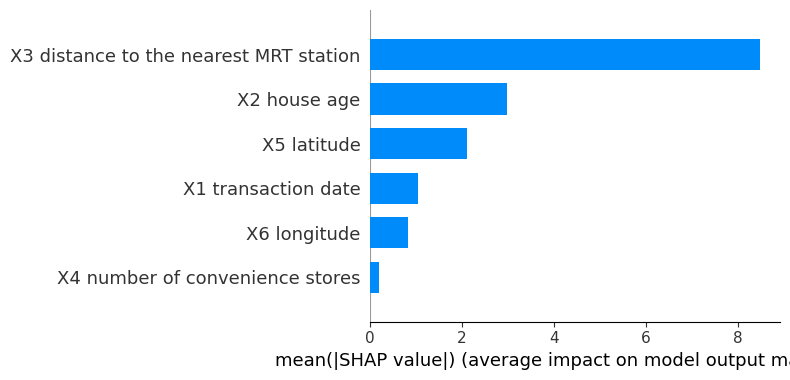

In [ ]:
#ερωτημα 8
import pandas as pd
import matplotlib.pyplot as plt
import shap

#8.1 Σημασία Συντελεστών (Γραμμικό Μοντέλο)
lin_reg.fit(X_train_scaled, y_train.values.ravel())
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': lin_reg.coef_})
print("8.1 Συντελεστές Γραμμικού Μοντέλου ---")
print(coef_df.sort_values(by='Coefficient', ascending=False))

# 8.2 Feature Importance (Ensemble Μοντέλο)
best_rf=grid_rf.best_estimator_
importances = best_rf.feature_importances_
feat_imp_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(feat_imp_df['Feature'], feat_imp_df['Importance'], color='skyblue')
plt.xlabel('Importance Score')
plt.title('8.2 Feature Importance (Random Forest)')
plt.gca().invert_yaxis()
plt.show()

# 8.3 & 8.4 SHAP Values
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test_scaled)

# 8.4 SHAP Summary Plot
print("\n--- 8.4 SHAP Summary Plot ---")
shap.summary_plot(shap_values, X_test_scaled, feature_names=X.columns)

# 8.4 SHAP Bar Plot
print("\n--- 8.4 SHAP Bar Plot ---")
shap.summary_plot(shap_values, X_test_scaled, feature_names=X.columns, plot_type="bar")